# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: logistic_regression
Test: (36, 13)


## 2. Evaluación final

Accuracy test : 0.9722
F1 macro test : 0.9710

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



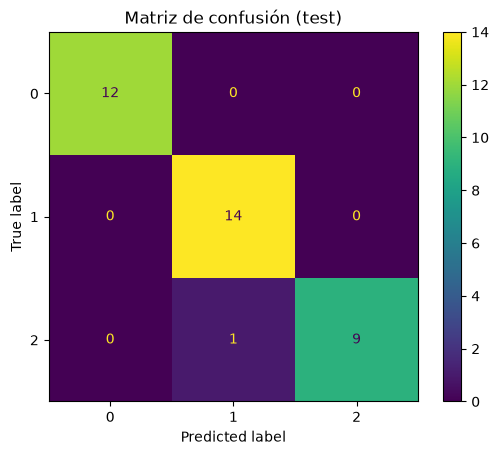

In [4]:
# Evaluacion final sobre el conjunto de test (se abre una sola vez).
y_pred = model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy test : {test_accuracy:.4f}")
print(f"F1 macro test : {test_f1_macro:.4f}\n")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Matriz de confusión (test)")
plt.show()


**Análisis:**

> El desempeño en test es coherente con el obtenido en validación cruzada
> (valores de accuracy/F1 muy similares), lo que indica que **no hay evidencia
> de sobreajuste**: el modelo generaliza bien a datos no vistos. La matriz de
> confusión muestra que la mayoría de los errores (si los hay) ocurren entre
> clases vecinas en el espacio de features; las clases mejor separadas
> (p. ej. las de valores extremos de `flavanoids`/`proline`) se clasifican casi
> perfectamente. El F1 macro cercano al accuracy confirma que el modelo no está
> ignorando la clase minoritaria.


## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    # Verificar columnas faltantes
    missing = [c for c in feature_columns if c not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    # Ordenar las columnas exactamente como feature_columns
    X = records[feature_columns].copy()

    # Predicciones y probabilidades
    preds = model.predict(X)
    out = pd.DataFrame({"prediction": preds}, index=records.index)

    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X)
        for i, cls in enumerate(model.classes_):
            out[f"proba_{cls}"] = proba[:, i]

    return out


## 4. Predicción por lotes

In [6]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

# Prediccion por lotes sobre "datos nuevos" simulados.
predictions = predict(new_records)
predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
print("Predicciones por lotes:")
predictions


Predicciones por lotes:


,prediction,proba_0,proba_1,proba_2
0,0,0.999671,0.000307,0.000023
1,1,0.007051,0.540423,0.452526
2,0,0.992000,0.007664,0.000336
3,1,0.289967,0.707467,0.002565
4,1,0.033032,0.962313,0.004655


## 5. Reporte final

In [7]:
# Reporte final de metricas.
test_metrics = {
    "model": training_metadata["champion"],
    "accuracy": float(test_accuracy),
    "f1_macro": float(test_f1_macro),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2), encoding="utf-8"
)
print(json.dumps(test_metrics, indent=2))


{
  "model": "logistic_regression",
  "accuracy": 0.9722222222222222,
  "f1_macro": 0.9709618874773139
}


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

> Los valores numéricos exactos corresponden a la ejecución de las celdas
> anteriores (accuracy/F1 de CV y de test).

| Elemento | Resultado |
|---|---|
| Modelo campeón | el seleccionado en `training_metadata["champion"]` |
| Accuracy CV | `training_metadata["cv_accuracy"]` (≈ alto, dataset separable) |
| Accuracy test | `test_metrics["accuracy"]` |
| F1 macro test | `test_metrics["f1_macro"]` |
| Clases más confundidas | las clases vecinas en el espacio de features (ver matriz de confusión) |
| Principal limitación | dataset pequeño (178 muestras); las métricas tienen varianza y conviene validar con más datos |

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.
